<a href="https://colab.research.google.com/github/pendo-kirahagaze/COU07506_240242484046_DSP_LAB/blob/main/COU07506_Week03_240242484046.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Manual Convolution: [1. 3. 6. 6. 4. 1.]
NumPy Convolution: [1 3 6 6 4 1]
Results Match: True

Pre-Lab Verification:
Manual: [ 2. -1.  3.  3. -1.  2.]
NumPy: [ 2 -1  3  3 -1  2]


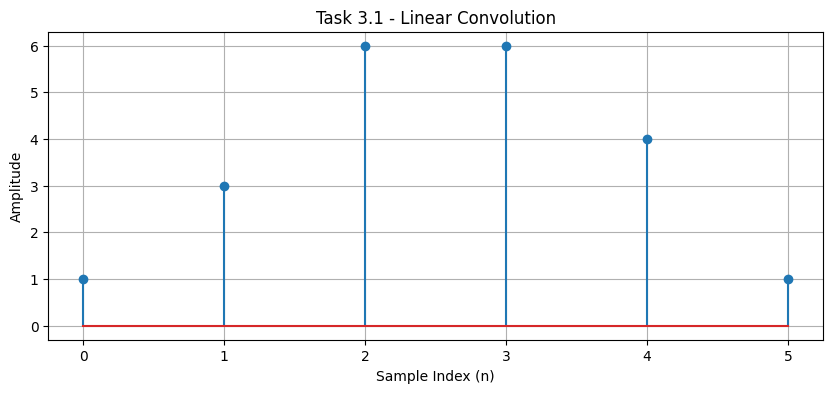

In [1]:

# WEEK 3 — TASK 3.1
# Convolution from the Definition
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
import time

# Manual convolution function
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k] * h[n-k]

    return y

# Example from laboratory manual
x = [1, 2, 3, 1]
h = [1, 1, 1]

manual_result = conv(x, h)
numpy_result = np.convolve(x, h)

print("Manual Convolution:", manual_result)
print("NumPy Convolution:", numpy_result)
print("Results Match:",
      np.allclose(manual_result, numpy_result))

# Verify pre-lab example
x2 = [1, -1, 2]
h2 = [2, 1, 0, 1]

print("\nPre-Lab Verification:")
print("Manual:", conv(x2, h2))
print("NumPy:", np.convolve(x2, h2))

# Plot convolution result
n = np.arange(len(manual_result))

plt.figure(figsize=(10, 4))
plt.stem(n, manual_result)

plt.title("Task 3.1 - Linear Convolution")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


In [2]:

# TASK 3.1 — Execution Time Comparison

rng = np.random.default_rng(0)

x = rng.standard_normal(2000)
h = rng.standard_normal(2000)

# Manual convolution timing
start = time.perf_counter()
y_manual = conv(x, h)
manual_time = time.perf_counter() - start

# NumPy convolution timing
start = time.perf_counter()
y_numpy = np.convolve(x, h)
numpy_time = time.perf_counter() - start

print(f"Manual Time: {manual_time:.6f} seconds")
print(f"NumPy Time: {numpy_time:.6f} seconds")

print("Results Match:",
      np.allclose(y_manual, y_numpy))

print(f"Speed-up: {manual_time/numpy_time:.2f}x")


Manual Time: 4.382793 seconds
NumPy Time: 0.001493 seconds
Results Match: True
Speed-up: 2934.61x


### Task 3.1 — Observation and Discussion

The manual convolution function was implemented using nested loops and compared with NumPy's built-in `np.convolve()` function.

Both methods produced matching results for the given signals.

For the first example, the convolution output was:

**y(n) = {1, 3, 6, 6, 4, 1}**

For the pre-lab example, the convolution output was:

**y(n) = {2, −1, 3, 3, −1, 2}**

**Execution Time Comparison:**

- Manual convolution time: 4.382793 seconds
- NumPy convolution time: 0.001493 seconds
- Speed-up: 2934.61x

NumPy's convolution function generally executes faster because it uses optimized compiled numerical routines instead of nested Python loops.

**Conclusion:** Linear convolution can be calculated directly from its mathematical definition, and the results can be verified using NumPy's built-in convolution function.

## Task 3.2 — Smoothing a Noisy Signal by Convolution

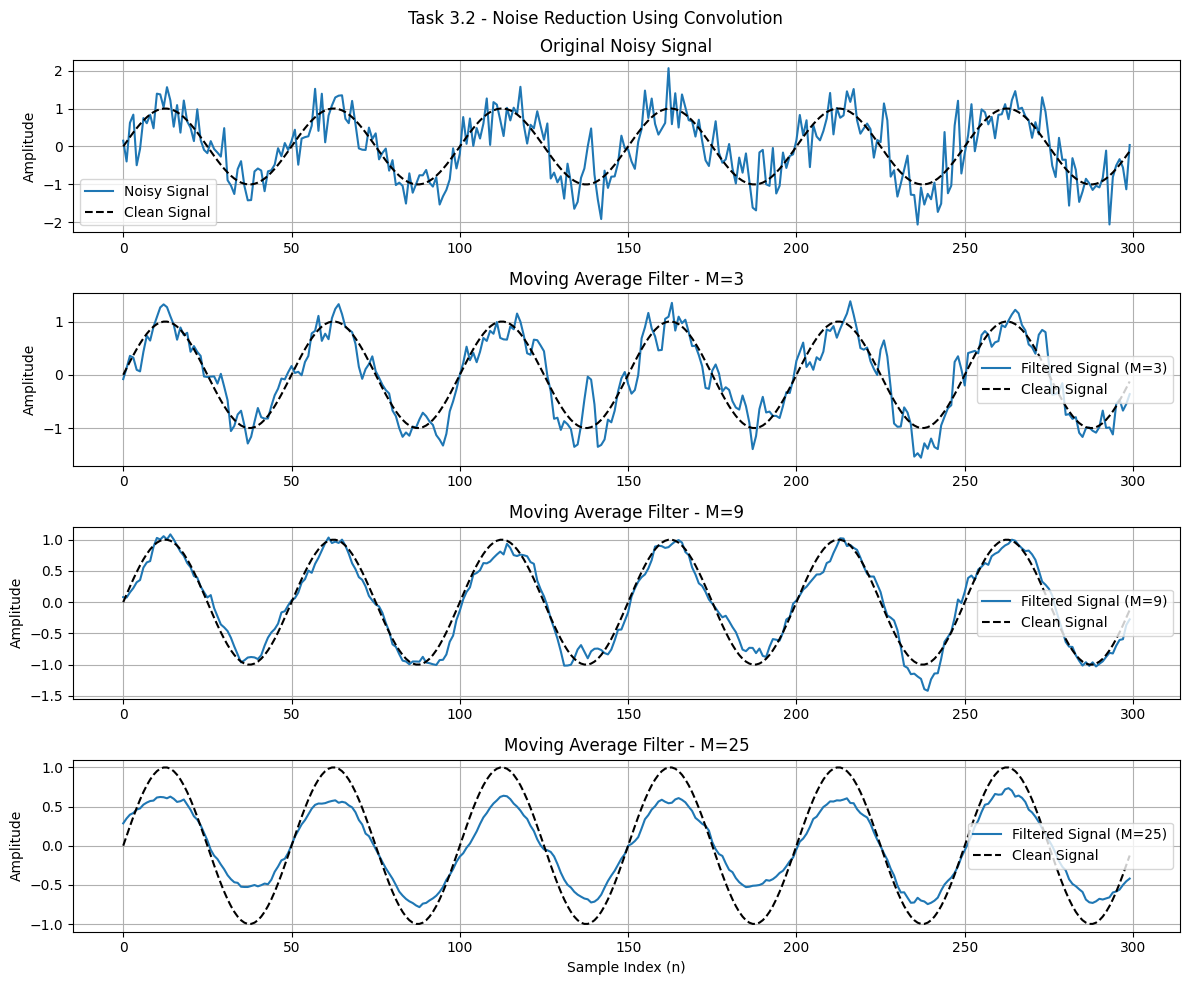

Task 3.2 Completed Successfully!


In [3]:

# WEEK 3 — TASK 3.2
# Smoothing a Noisy Signal by Convolution
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt

# Generate sample indices
n = np.arange(300)

# Generate clean sine wave
clean = np.sin(2 * np.pi * n / 50)

# Add Gaussian noise
rng = np.random.default_rng(42)
noise = 0.5 * rng.standard_normal(300)
x = clean + noise

# Moving-average filter lengths
M_values = [3, 9, 25]

# Create four graphs
fig, axes = plt.subplots(4, 1, figsize=(12, 10))

# Original noisy signal
axes[0].plot(n, x, label="Noisy Signal")
axes[0].plot(n, clean, "k--",
             label="Clean Signal")
axes[0].set_title("Original Noisy Signal")
axes[0].set_ylabel("Amplitude")
axes[0].legend()
axes[0].grid(True)

# Apply moving-average filters
for i, M in enumerate(M_values):

    h = np.ones(M) / M

    # Apply convolution
    y = np.convolve(x, h, mode="same")

    axes[i+1].plot(n, y,
                   label=f"Filtered Signal (M={M})")
    axes[i+1].plot(n, clean, "k--",
                   label="Clean Signal")

    axes[i+1].set_title(
        f"Moving Average Filter - M={M}"
    )
    axes[i+1].set_ylabel("Amplitude")
    axes[i+1].legend()
    axes[i+1].grid(True)

axes[-1].set_xlabel("Sample Index (n)")

plt.suptitle(
    "Task 3.2 - Noise Reduction Using Convolution"
)
plt.tight_layout()
plt.show()

print("Task 3.2 Completed Successfully!")


### Task 3.2 — Observation and Discussion

A sine wave was generated and Gaussian noise was added to simulate a noisy signal.

Three moving-average filters with lengths M = 3, M = 9 and M = 25 were applied using convolution.

**M = 3:** The filter slightly reduced the noise while preserving most of the original signal.

**M = 9:** The filter produced a smoother waveform with less noise.

**M = 25:** The filter provided stronger smoothing but also reduced the amplitude of the original sine wave.

**Trade-off:**

Increasing the filter length improves noise reduction but can introduce signal distortion.

**Conclusion:** Moving-average filtering is useful for reducing noise in digital signals. However, an appropriate filter length must be selected to balance noise reduction and signal preservation.

## Task 3.3 — Testing Linearity and Time-Invariance Numerically

In [4]:

# WEEK 3 — TASK 3.3
# Testing Linearity and Time-Invariance
# Registration Number: 240242484046

import numpy as np

# Generate random input signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Constants for linearity testing
a, b = 2.0, -3.0

# Define the three systems
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "moving average": lambda x:
        np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Test system properties
for name, T in systems.items():

    # Test linearity using superposition
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Delay input by 5 samples
    xd = np.concatenate(
        [np.zeros(5), x1]
    )[:50]

    # Delay output by 5 samples
    yd = np.concatenate(
        [np.zeros(5), T(x1)]
    )[:50]

    # Test time-invariance
    tinv = np.allclose(T(xd), yd)

    print(
        f"{name:15s} "
        f"linear={linear} "
        f"time-invariant={tinv}"
    )

print("\nTask 3.3 Completed Successfully!")


x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True

Task 3.3 Completed Successfully!


### Task 3.3 — Observation and Discussion

Three digital systems were tested for linearity and time-invariance using Python.

**1. Squaring System — x²(n)**

The system is nonlinear because it does not satisfy the superposition principle. However, it is time-invariant because delaying the input produces the same result as delaying the output.

**2. Time-Dependent System — nx(n)**

The system is linear because it satisfies superposition. However, it is time-varying because the output depends explicitly on the sample index n.

**3. Moving-Average Filter**

The moving-average filter is both linear and time-invariant. It satisfies superposition, and delaying the input produces an equally delayed output.

**Conclusion:**

Among the three systems tested, only the moving-average filter is a Linear Time-Invariant (LTI) system.

## Task 3.4 — Finding a Hidden Delay with Cross-Correlation

True Delay: 37 samples
Estimated Delay: 37 samples
Estimated Distance: 12.691 m


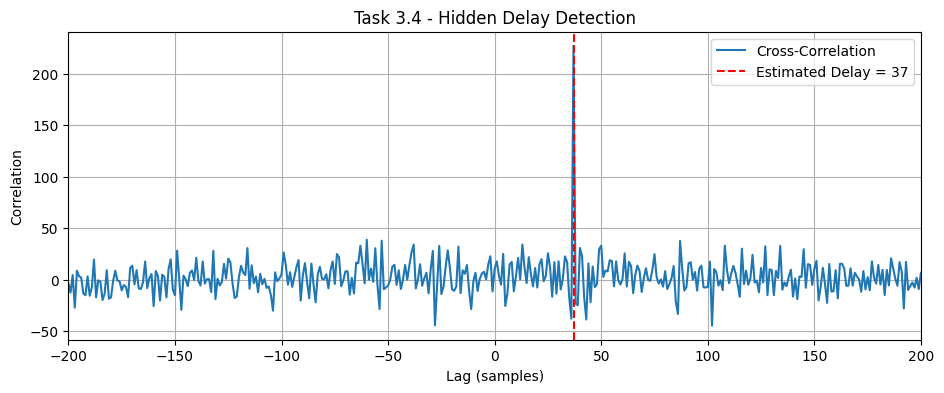

In [5]:

# WEEK 3 — TASK 3.4
# Finding a Hidden Delay with Cross-Correlation
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

rng = np.random.default_rng(1)

# Sampling rate and transmitted signal
fs = 1000
x = rng.standard_normal(500)

# Actual delay
true_delay = 37

# Create delayed signal with noise
clean_y = np.concatenate([
    np.zeros(true_delay), 0.6*x
])[:500]

noise = rng.standard_normal(500)
y = clean_y + 0.5*noise

# Compute cross-correlation
r = signal.correlate(y, x, mode="full")

lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

# Estimate delay
estimated_delay = lags[np.argmax(r)]

print("True Delay:", true_delay, "samples")
print("Estimated Delay:", estimated_delay, "samples")

# Calculate distance
speed_of_sound = 343

distance = estimated_delay/fs * speed_of_sound

print(f"Estimated Distance: {distance:.3f} m")

# Plot cross-correlation
plt.figure(figsize=(11, 4))

plt.plot(lags, r, label="Cross-Correlation")

plt.axvline(
    estimated_delay,
    color="red",
    linestyle="--",
    label=f"Estimated Delay = {estimated_delay}"
)

plt.xlim(-200, 200)
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.title("Task 3.4 - Hidden Delay Detection")
plt.legend()
plt.grid(True)
plt.show()


In [6]:

# TASK 3.4 — Effect of Noise on Delay Estimation

noise_levels = [0.5, 1, 2, 4]

print("Noise Std | Estimated Delay | Correct")
print("--------------------------------------")

for std in noise_levels:

    # Use the same noise pattern at each level
    y_noisy = clean_y + std*noise

    # Cross-correlation
    r = signal.correlate(y_noisy, x, mode="full")
    lags = signal.correlation_lags(
        len(y_noisy), len(x), mode="full"
    )

    estimated = lags[np.argmax(r)]
    correct = estimated == true_delay

    print(
        f"{std:9.1f} | "
        f"{estimated:15d} | {correct}"
    )

print("\nTask 3.4 Completed!")


Noise Std | Estimated Delay | Correct
--------------------------------------
      0.5 |              37 | True
      1.0 |              37 | True
      2.0 |              37 | True
      4.0 |              87 | False

Task 3.4 Completed!


### Task 3.4 — Observation and Discussion

Cross-correlation was used to estimate the time delay between a transmitted signal and a noisy received signal.

The original signal was delayed by 37 samples. Using cross-correlation, the delay was estimated by finding the lag corresponding to the maximum correlation.

**Distance Calculation:**

Sampling frequency = 1,000 Hz

Delay = 37 samples

Time delay = 37/1,000 = 0.037 seconds

Speed of sound = 343 m/s

Distance = 343 × 0.037

**Distance = 12.691 meters**

**Effect of Noise:**

Increasing the noise standard deviation makes the correlation peak more difficult to identify reliably.

The estimated delays at noise standard deviations of 0.5, 1, 2 and 4 were:

Noise Std | Estimated Delay | Correct
--------------------------------------
      0.5 |              37 | True
      1.0 |              37 | True
      2.0 |              37 | True
      4.0 |              87 | False

**Conclusion:**

Cross-correlation can be used to estimate delays between signals even when noise is present. However, sufficiently strong noise may cause incorrect delay estimates.

## Task 3.5 — Difference Equation

n | Recursion | lfilter | Theory
----------------------------------------
0 | 1.000000 | 1.000000 | 1.000000
1 | 1.750000 | 1.750000 | 1.750000
2 | 1.187500 | 1.187500 | 1.187500
3 | 0.671875 | 0.671875 | 0.671875
4 | 0.355469 | 0.355469 | 0.355469
5 | 0.182617 | 0.182617 | 0.182617
6 | 0.092529 | 0.092529 | 0.092529
7 | 0.046570 | 0.046570 | 0.046570
8 | 0.023361 | 0.023361 | 0.023361
9 | 0.011700 | 0.011700 | 0.011700

Manual vs lfilter: True
Manual vs Theory: True


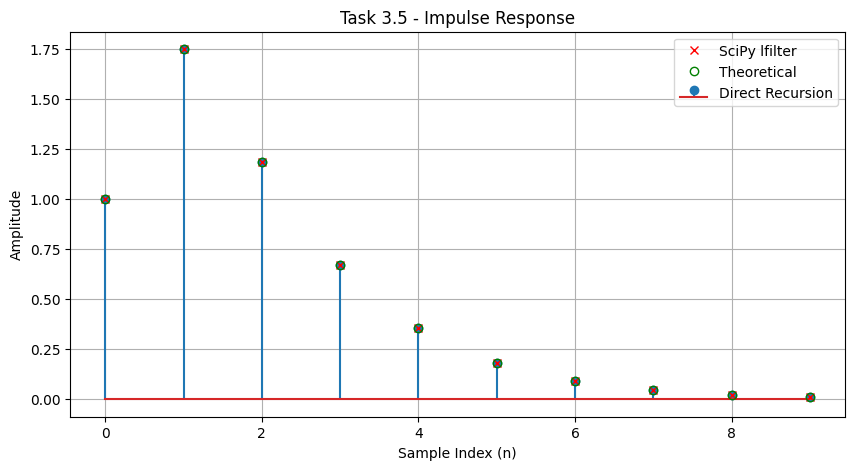

In [7]:

# WEEK 3 — TASK 3.5
# Difference Equation
# Registration Number: 240242484046

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Define sample indices
n = np.arange(10)

# Unit impulse input
impulse = np.zeros(10)
impulse[0] = 1

# METHOD 1: Direct Recursion
h_manual = np.zeros(10)

for i in range(10):
    x0 = impulse[i]
    x1 = impulse[i-1] if i >= 1 else 0
    y1 = h_manual[i-1] if i >= 1 else 0
    y2 = h_manual[i-2] if i >= 2 else 0

    h_manual[i] = x0 + x1 + 0.75*y1 - 0.125*y2

# METHOD 2: SciPy lfilter
b = [1, 1]
a = [1, -0.75, 0.125]

h_lfilter = signal.lfilter(b, a, impulse)

# METHOD 3: Theoretical Formula
h_theory = 6*(0.5**n) - 5*(0.25**n)

# Display results
print("n | Recursion | lfilter | Theory")
print("----------------------------------------")

for i in range(10):
    print(
        f"{i} | {h_manual[i]:.6f} | "
        f"{h_lfilter[i]:.6f} | "
        f"{h_theory[i]:.6f}"
    )

print("\nManual vs lfilter:",
      np.allclose(h_manual, h_lfilter))

print("Manual vs Theory:",
      np.allclose(h_manual, h_theory))

# Plot results
plt.figure(figsize=(10, 5))

plt.stem(n, h_manual,
         label="Direct Recursion")

plt.plot(n, h_lfilter, "rx",
         label="SciPy lfilter")

plt.plot(n, h_theory, "go",
         fillstyle="none",
         label="Theoretical")

plt.title("Task 3.5 - Impulse Response")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


Final Step Response: 5.333333333333333
Theoretical H(1): 5.333333333333333
Results Match: True


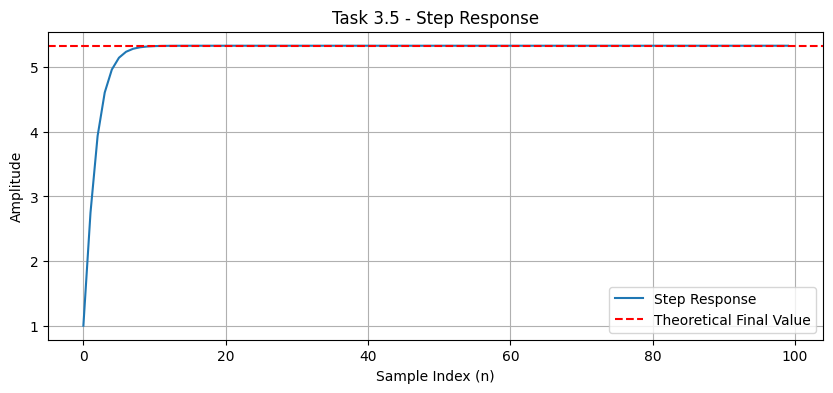

In [8]:

# TASK 3.5 — Step Response

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# System coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Unit step input
n = np.arange(100)
step = np.ones(100)

# Calculate step response
y_step = signal.lfilter(b, a, step)

# Theoretical final value
H1 = sum(b) / sum(a)

print("Final Step Response:", y_step[-1])
print("Theoretical H(1):", H1)

print("Results Match:",
      np.isclose(y_step[-1], H1))

# Plot step response
plt.figure(figsize=(10, 4))

plt.plot(n, y_step,
         label="Step Response")

plt.axhline(H1,
            color="red",
            linestyle="--",
            label="Theoretical Final Value")

plt.title("Task 3.5 - Step Response")
plt.xlabel("Sample Index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


### Task 3.5 — Observation and Discussion

The impulse response was calculated using three methods: direct recursion, SciPy's `lfilter()` function, and the theoretical closed-form expression.

All three methods produced matching results, confirming the correctness of the implementation.

The impulse response initially increased before gradually decreasing toward zero.

The step response approached a final value of approximately **5.3333**, agreeing with the theoretical result.

**System Classification:**

The system is an Infinite Impulse Response (IIR) system because its output depends on previous output values.

The system is stable because its poles are located at 0.5 and 0.25, both inside the unit circle.

**Conclusion:**

The difference equation can be solved using direct recursion and digital filtering functions. Both methods agree with the theoretical response, confirming that the system is stable.

# WEEK 3 — PRE-LAB AND ANALYSIS QUESTIONS

## A. Pre-Lab Questions

### Question 1: Convolve x(n) = {1, −1, 2} with h(n) = {2, 1, 0, 1} by hand.

**Answer:**

Given:

- x(n) = {1, −1, 2}
- h(n) = {2, 1, 0, 1}

Using linear convolution:

y(n) = Σ x(k)h(n − k)

The output samples are:

- y(0) = 1(2) = 2
- y(1) = 1(1) − 1(2) = −1
- y(2) = 1(0) − 1(1) + 2(2) = 3
- y(3) = 1(1) − 1(0) + 2(1) = 3
- y(4) = −1(1) + 2(0) = −1
- y(5) = 2(1) = 2

**Final result:**

y(n) = **{2, −1, 3, 3, −1, 2}**

The calculated result agrees with the output of NumPy's `np.convolve()` function.

### Question 2: Is y(n) = nx(n) time-invariant? Show your test.

**Answer:**

The system is time-varying because its output depends explicitly on the sample index n.

For a delayed input x(n − k):

T{x(n − k)} = nx(n − k)

However, delaying the original output gives:

y(n − k) = (n − k)x(n − k)

These expressions are generally different.

**Conclusion:** The system y(n) = nx(n) is not time-invariant.

---

## B. Analysis Questions

### Question 1: Why is np.convolve much faster than a double loop? What is the number of multiplications for lengths L and M?

**Answer:**

NumPy's `np.convolve()` is faster because it uses optimized compiled numerical routines rather than executing nested loops in Python.

For direct linear convolution, the number of multiplications is:

**L × M**

For two sequences containing 2,000 samples each:

2,000 × 2,000 = **4,000,000 multiplications**

Both methods produce the same result, but NumPy generally executes much faster.

### Question 2: Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?

**Answer:**

| System | Linear | Time-Invariant | LTI |
|---|---|---|---|
| x²(n) | No | Yes | No |
| nx(n) | Yes | No | No |
| Moving average | Yes | Yes | Yes |

Only the moving-average filter is a Linear Time-Invariant (LTI) system.

These properties can be predicted mathematically by testing the superposition principle and determining whether delaying the input produces an equally delayed output.

### Question 3: Give two engineering applications of cross-correlation in Tanzania.

**Answer:**

**1. Water Pipeline Leak Detection**

Cross-correlation can be used to estimate time delays between acoustic signals detected by sensors installed along water pipelines.

Engineers can use these delays to estimate the position of underground leaks, potentially reducing water losses in distribution networks.

**2. Airport Radar Systems**

Cross-correlation can be applied in radar signal processing to detect received reflections and estimate their delays.

This technique can help determine distances to aircraft and support radar-based surveillance systems at airports.

### Question 4: Is the system in Task 3.5 FIR or IIR? Is it stable? Justify using the impulse response.

**Answer:**

The system is an **Infinite Impulse Response (IIR)** system because its output depends on previous output values.

Its impulse response is:

h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ, for n ≥ 0

The impulse response continues indefinitely but decreases toward zero.

The system poles are:

- p₁ = 0.5
- p₂ = 0.25

Both poles are inside the unit circle, and the impulse response is absolutely summable.

Therefore, the system is **BIBO stable**.

---

## C. AI-Use Statement

ChatGPT (OpenAI) was used to assist with understanding convolution, correlation, linearity, time-invariance and difference equations.

The tool provided Python code examples, mathematical explanations and guidance on interpreting laboratory results.

The practical code was executed in Google Colab. Convolution results were compared using manual calculations and NumPy functions, while the impulse-response calculations were compared using direct recursion, SciPy's `lfilter()` and the theoretical expression.

